In [2]:
import ipynb.fs.full.linear_regression as lr

In [ ]:
scan = "0001_circle"
data, cx, cy, hough_params =  lr.read_the_data(scan)

{'enabled': True, 'min_radius': 4, 'max_radius': 7, 'param1': 100, 'param2': 22, 'min_dist': 50, 'stabilise': True, 'hold_frames': 3}


,point,time,x,y,x_rb,y_rb,s0,s1,s2,strain,frame_id,n_circles,cx,cy,radius
0,0,4.1617,3.000000e-01,0.000000,2.999515e-01,-5.921189e-17,0,-1330,1330,0.000000,283041,1,294,204,6
1,1,5.5738,2.954423e-01,0.052094,2.954410e-01,5.208333e-02,267,-1443,1177,0.000081,283061,1,292,200,6
2,2,7.0019,2.819078e-01,0.102606,2.819093e-01,1.026042e-01,525,-1513,987,-0.000081,283081,1,294,192,6
3,3,8.4278,2.598076e-01,0.150000,2.598076e-01,1.500000e-01,768,-1536,768,0.000000,283101,1,296,186,6
4,4,9.7842,2.298133e-01,0.192836,2.298125e-01,1.928385e-01,987,-1513,525,-0.000081,283120,1,300,178,6
5,5,11.2122,1.928363e-01,0.229813,1.928260e-01,2.298177e-01,1177,-1443,267,0.000081,283140,1,304,172,6
6,6,12.6403,1.500000e-01,0.259808,1.499758e-01,2.597656e-01,1330,-1330,0,0.000000,283160,1,310,168,6
7,7,14.0681,1.026060e-01,0.281908,1.026150e-01,2.819010e-01,1443,-1177,-267,-0.000081,283180,1,318,164,6
8,8,15.4961,5.209445e-02,0.295442,5.209684e-02,2.954427e-01,1513,-987,-525,0.000081,283200,1,324,162,6
9,9,16.9381,1.836970e-17,0.300000,4.185242e-17,3.000000e-01,1536,-768,-768,0.000000,283220,1,332,162,6


AttributeError: 'DataFrame' object has no attribute 'len'

(<Figure size 640x480 with 2 Axes>, <Axes: xlabel='cy', ylabel='cx'>)

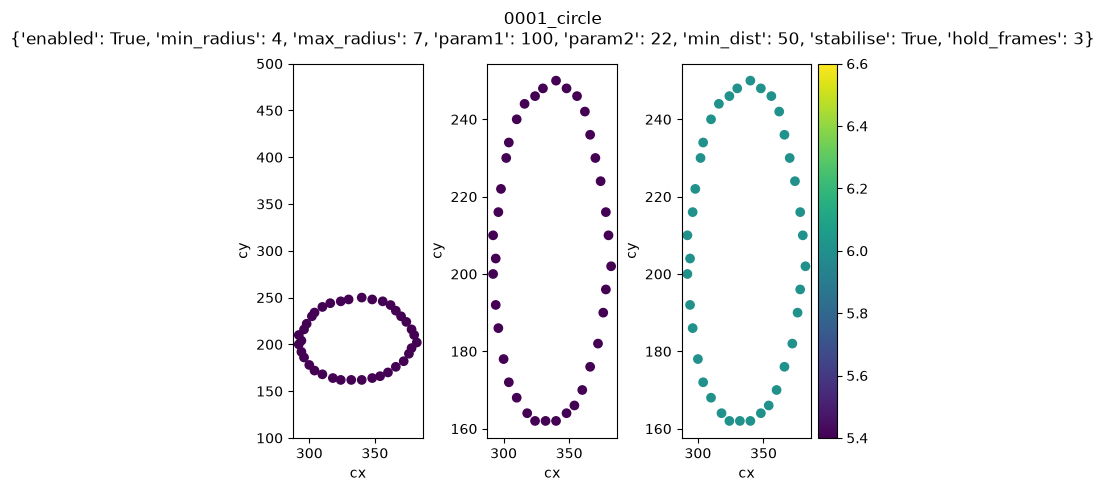

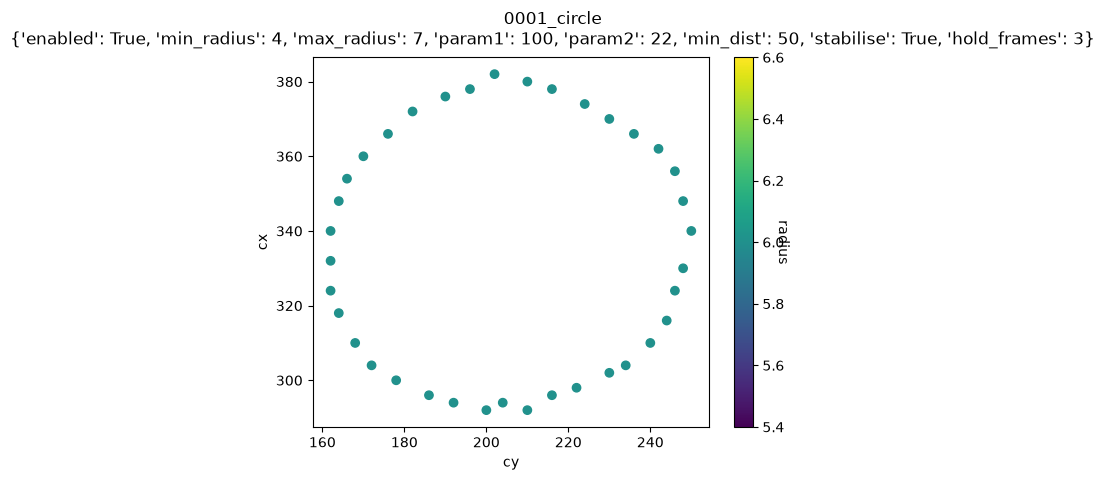

In [4]:
lr.subplot_linear(scan, hough_params, cx, cy, data["radius"], 100, 500, False)
lr.single_plot(scan, hough_params, cy, cx,  data["radius"], None, None, False)

Radius (by eye on the graph): 
y :  ~ (380 - 290) / 2 = 45px
45px * 0.1 / 11 = 0.41 mm

x: ~ (250 - 160) / 2 = 45 px = same ! :) 

Scan: t = np.linspace(0, 2 * np.pi, 37)
d = run_scan(list(zip(0.3 * np.cos(t), 0.3 * np.sin(t))), Circles(), name="circle")
--> 0.3 is the radius --> approx correct. 

stats.linregress slope and intercept -145.15769453739472 205.0810810810811


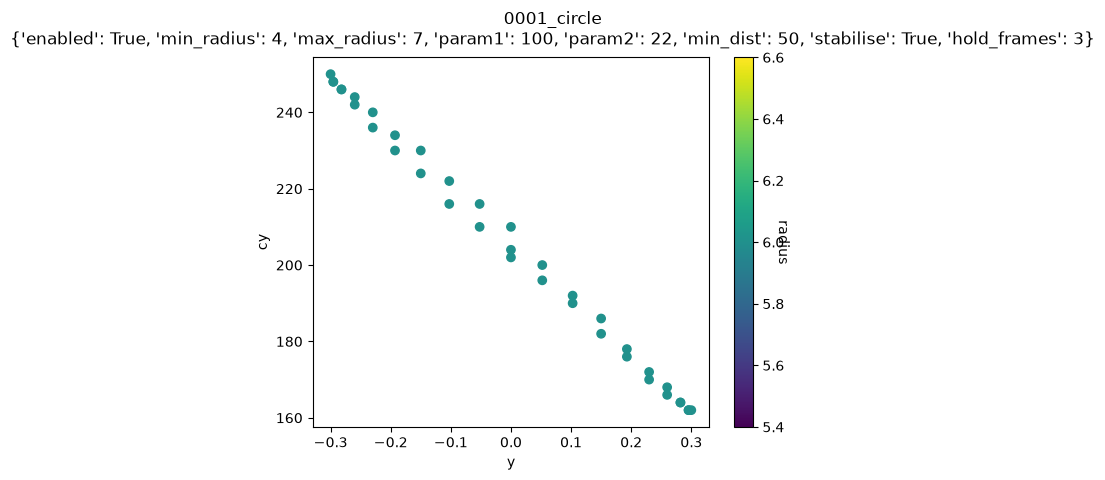

In [5]:
fig, ax = lr.single_plot(scan, hough_params, data["y"], cy, data["radius"], None, None, True)

stats.linregress slope and intercept -144.7313864083063 335.9302544843917


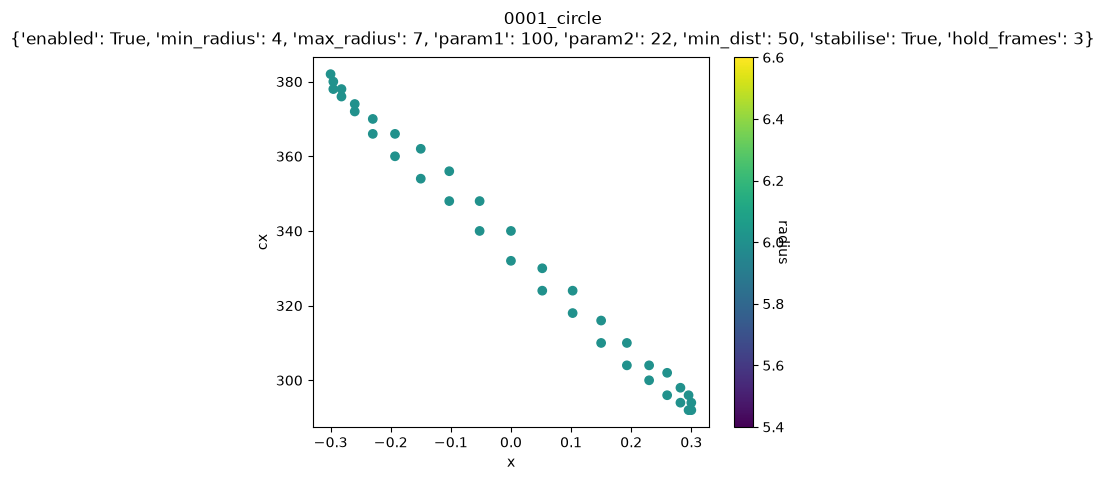

In [6]:
fig, ax = lr.single_plot(scan, hough_params, data["x"], cx, data["radius"], None, None, True)

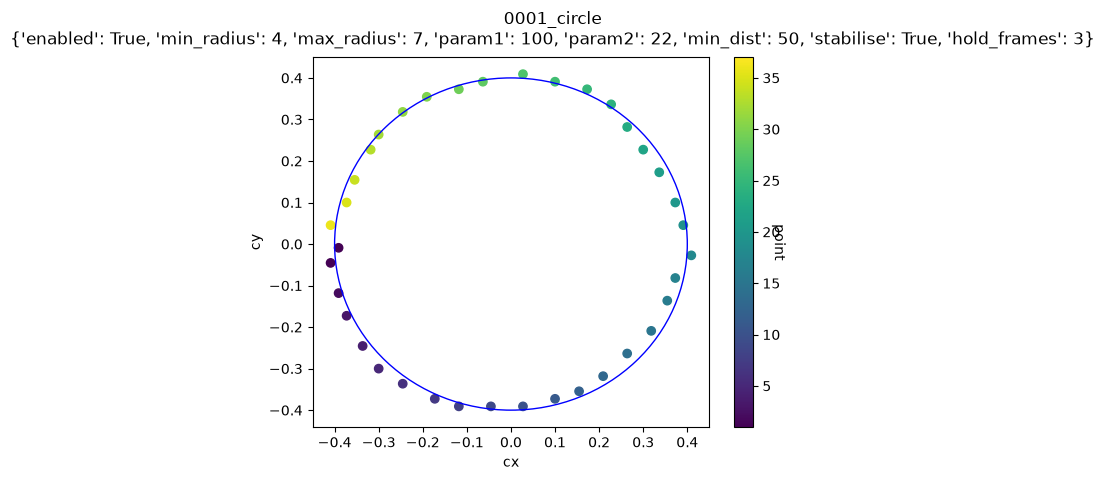

In [45]:
import matplotlib.pyplot as plt
from scipy.optimize import least_squares 
import numpy as np

fig, ax = plt.subplots()
fig.suptitle(scan + "\n" + str(hough_params))
ax0 = ax.scatter((cx - 150)/110 - 1.7, (cy - 205)/110, c=data["point"], cmap='viridis', vmin=1, vmax=data["point"].size)
ax.set_xlabel("cx")
ax.set_ylabel("cy")

cbar = fig.colorbar(ax0)
cbar.ax.set_ylabel("point", rotation=270)


def circle(x, y): 
    return x**2 + y **2
# t = np.linspace(0, 2 * np.pi, 37)
# ax.plot(circle((0.3 * np.cos(t), 0.3 * np.sin(t)))))
ax.add_patch(plt.Circle((0,0), 0.4, color="blue", fill=False))
# res_lsq = least_squares(circle, cx)
# if fit: 
#     slope, intercept, r_value, p_value, std_err = stats.linregress(x_nonan,y_nonan)
#     xseq = np.linspace(x_nonan.iloc[-1], x_nonan.iloc[0], num=100)
#     ax.plot(xseq, intercept + slope * xseq, color="k", lw=2.5)
#     print("stats.linregress slope and intercept", slope, intercept)


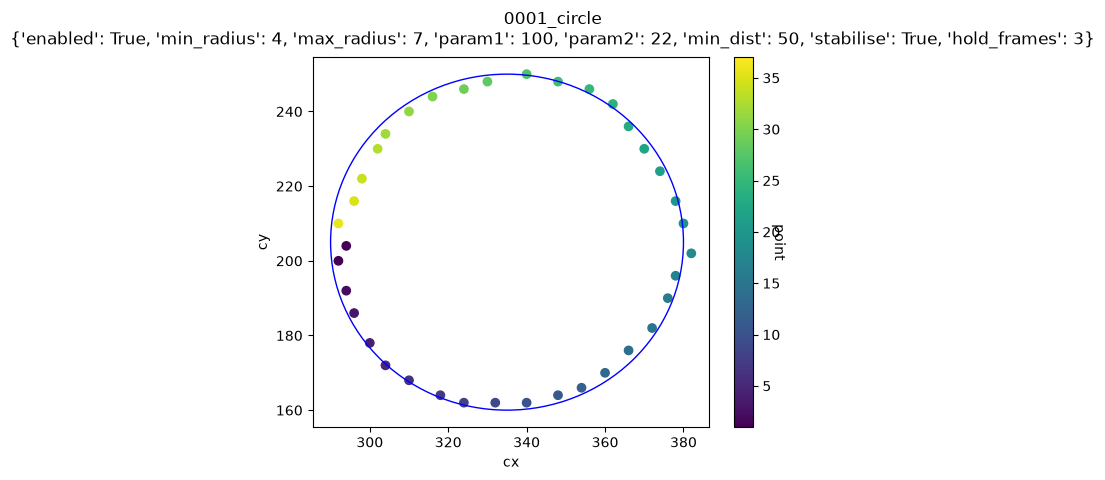

In [55]:
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, curve_fit
import numpy as np

fig, ax = plt.subplots()
fig.suptitle(scan + "\n" + str(hough_params))
ax0 = ax.scatter(cx, cy, c=data["point"], cmap='viridis', vmin=1, vmax=data["point"].size)
ax.set_xlabel("cx")
ax.set_ylabel("cy")

cbar = fig.colorbar(ax0)
cbar.ax.set_ylabel("point", rotation=270)


def circle(x, y): 
    return x**2 + y**2
# t = np.linspace(0, 2 * np.pi, 37)
# ax.plot(circle((0.3 * np.cos(t), 0.3 * np.sin(t)))))
ax.add_patch(plt.Circle((335,205), 45, color="blue", fill=False))
# res_lsq = least_squares(circle, cx)

In [66]:
x = (cx - 150)/110 - 1.7
y = (cy - 205)/110

def objective(x, y):
    return np.sqrt(x**2 + y**2)

popt, _ = curve_fit(objective, x, y)
print(popt)

x_new = t = np.linspace(0, 2 * np.pi, 37)

r = popt

# r_new = objective(x_new, )

[-3.89735166e-07]


/tmp/ipykernel_3425833/2776883102.py:7: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(objective, x, y)


In [74]:
import numpy as np
from scipy.optimize import least_squares

def fit_circle_geometric(x, y):
    """
    Fits a circle by minimizing geometric distance residuals.
    Returns: xc (center x), yc (center y), R (radius)
    """
    x = np.asarray(x)
    y = np.asarray(y)
    
    # 1. Estimate initial guess using the mean of the data
    x_m = np.mean(x)
    y_m = np.mean(y)
    r_m = np.mean(np.sqrt((x - x_m)**2 + (y - y_m)**2))
    initial_guess = [x_m, y_m, r_m]
    
    # 2. Define the objective function (distance residual)
    def equations(params):
        xc, yc, R = params
        # Distance from each point to the proposed center minus proposed radius
        return np.sqrt((x - xc)**2 + (y - yc)**2) - R
    
    # 3. Optimize
    result = least_squares(equations, initial_guess)
    
    return result.x[0], result.x[1], result.x[2]

# Example Usage:
xc, yc, R = fit_circle_geometric(cx, cy)
print(f"Geometric Center: ({xc:.4f}, {yc:.4f}), Radius: {R:.4f}")


Geometric Center: (335.9122, 204.9860), Radius: 43.6028


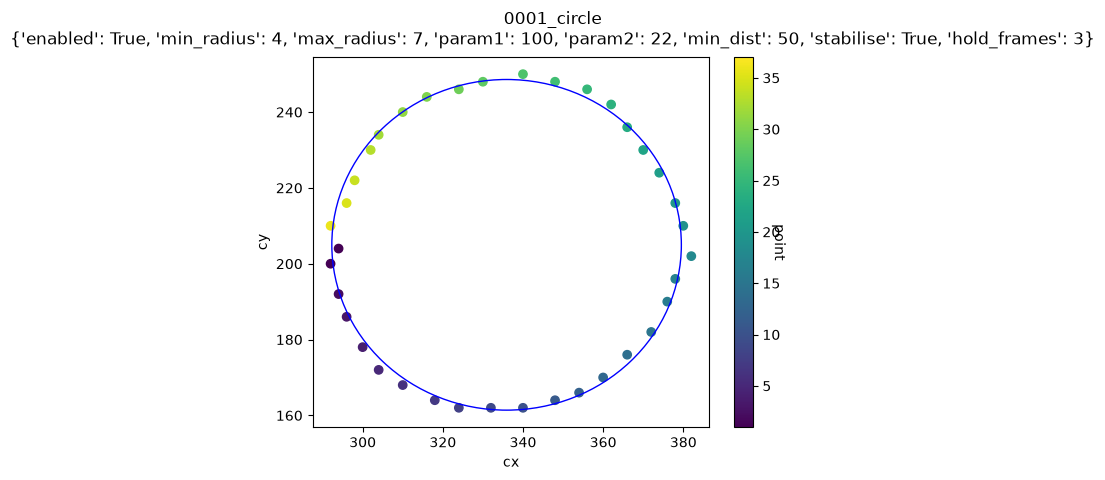

In [75]:
fig, ax = plt.subplots()
fig.suptitle(scan + "\n" + str(hough_params))
ax0 = ax.scatter(cx, cy, c=data["point"], cmap='viridis', vmin=1, vmax=data["point"].size)
ax.set_xlabel("cx")
ax.set_ylabel("cy")

cbar = fig.colorbar(ax0)
cbar.ax.set_ylabel("point", rotation=270)

ax.add_patch(plt.Circle((xc,yc), R, color="blue", fill=False))


In [ ]:
t = np.linspace(0, 2 * np.pi, 37)
d = (list(zip(0.3 * np.cos(t) + 0.4, 0.3 * np.sin(t) + -.4)))
d
print((zip(0.3 * np.cos(t), 0.3 * np.sin(t))))
print(d)

[(np.float64(0.7), np.float64(0.4)), (np.float64(0.6954423259036624), np.float64(0.45209445330007914)), (np.float64(0.6819077862357725), np.float64(0.5026060429977006)), (np.float64(0.6598076211353316), np.float64(0.55)), (np.float64(0.6298133329356934), np.float64(0.5928362829059618)), (np.float64(0.5928362829059618), np.float64(0.6298133329356934)), (np.float64(0.55), np.float64(0.6598076211353316)), (np.float64(0.5026060429977006), np.float64(0.6819077862357725)), (np.float64(0.45209445330007914), np.float64(0.6954423259036624)), (np.float64(0.4), np.float64(0.7)), (np.float64(0.3479055466999209), np.float64(0.6954423259036624)), (np.float64(0.2973939570022994), np.float64(0.6819077862357725)), (np.float64(0.2500000000000001), np.float64(0.6598076211353316)), (np.float64(0.20716371709403822), np.float64(0.6298133329356934)), (np.float64(0.17018666706430666), np.float64(0.5928362829059619)), (np.float64(0.1401923788646684), np.float64(0.55)), (np.float64(0.11809221376422752), np.floa